# The overnight jump equation: closed-form estimation, and what it finds

A trading day and the night that follows it split the move from one opening print to the next
into two pieces that do not overlap. The day is a curve, $X_t(s)$, the cumulative intraday
return at a fraction $s$ of the session elapsed; the night is a scalar, $J_{t+1} = \log
\mathrm{Open}_{t+1} - \log \mathrm{Close}_t$. Together they are the whole return, and separately
neither contains the other: `notebooks/shang_replication.ipynb` forecasts the curve and cannot
see the jump at all, because anchoring every curve at its own opening price is exactly what
deletes it.

This notebook estimates the equation for the other half:

$$ J_t \;=\; a + \gamma J_{t-1} + \int_0^1 \delta(u)\,X_{t-1}(u)\,\mathrm{d}u
   + \mathbf{z}_t^\top \mathbf{k} + \eta_t, \qquad
   \eta_t \overset{\text{iid}}{\sim} \mathcal{N}(0, \sigma_J^2). $$

Expanding $\delta$ in the empirical principal components of the curves turns the functional term
into $\mathbf{d}^\top \boldsymbol\psi_{t-1}$, and the model into a linear regression on $(1,
J_{t-1}, \boldsymbol\psi_{t-1}^\top, \mathbf{z}_t^\top)$. Every regressor there is measurable at
the close of $t-1$: $\boldsymbol\psi$ enters lagged because it describes the session before the
jump, $\mathbf{z}$ contemporaneously because it describes the session that closed as the jump
was forming. With predetermined regressors and Gaussian homoskedastic errors the conditional
likelihood is that of a linear model, so **the conditional MLE is ordinary least squares and
closed form**, with no sampler to diagnose and no optimiser to fail. That is the first thing
this notebook establishes, and it is what a later Bayesian fit gets checked against.

Three things then get in the way of reading the estimate straight off, and each has a section
below. The scores are *generated regressors*, estimated from the same curves. The MLE *shrinks
nothing*, so the $\mathbf{d}$ block is as wide as the number of components retained rather than
as the number carrying signal. And the innovations on real jumps are *not* homoskedastic, even
where the conditional mean is right.

The last section asks the equation of real sessions, where `notebooks/overnight_jumps.ipynb`
has already established what there is to find: the direction of an overnight move is close to
unforecastable and its size is not. `jump/README.md` documents the implementation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from fts_research.core import style
from fts_research.far.far_est import fpca
from fts_research.fdaSP import intraday as itd
from fts_research.jump import jump_dgp as dgp
from fts_research.jump import jump_eq as je

style.use(plt)

MLE, LASSO = style.CATEGORICAL[0], style.CATEGORICAL[2]

## 1. A design where the answer is known

The simulation goes the long way round, because the short way would make the problem easier than
it is. Curves are drawn on an intraday grid and anchored at zero, and the signal driving the
jump recursion is $\int \delta\,X_{t-1}$ integrated **on the grid** under `core.quadrature`'s
trapezium rule, not through the scores. Whatever $\delta$ has outside the span of the retained
components goes into the equation anyway and is unavailable to the estimator, exactly as on
real data.

The scores are then recovered by running `far.far_est.fpca` on the simulated curves, so what
the estimator receives is generated regressors. That fixes what "recovery" can mean: the
loadings it can hope to find are $d_k = \langle \delta, \hat\phi_k\rangle$ against the
*estimated* eigenfunctions, computed after the decomposition rather than before it. Comparing
an estimate with a target in a different basis and calling the difference bias is the mistake
this avoids.

The chosen $\delta(u) = 0.8\,\sin(\pi u)\,u$ loads on the late session, which is the shape a
"the last hour is what matters" hypothesis would have. `snr` is the signal-to-noise convention
`truncFLR.HH_dgp` and `fdaSP.SBC_sim` use, so this design sits on the same scale as the rest
of the repository's.

260 sessions, 5 components retained, sigma_J = 0.1855 at snr = 4
true loadings against the estimated basis: [ 0.2772  0.0944 -0.0129 -0.0626 -0.0068]


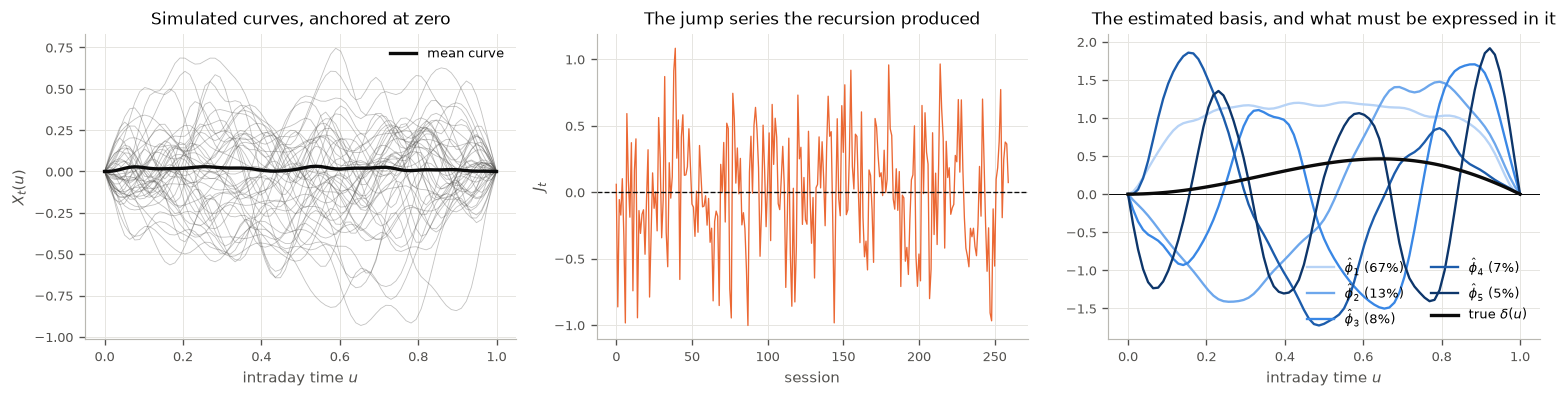

In [2]:
n_grid, n_sessions, M = 79, 260, 5
grid = np.linspace(0, 1, n_grid)
delta_true = 0.8 * np.sin(np.pi * grid) * grid
a_true, gamma_true = 0.05, 0.15
k_true = np.array([0.30, 0.0, -0.20])           # three covariates, the middle one inert

sim = dgp.simulate_curves_and_jumps(
    n=n_sessions, a=a_true, gamma=gamma_true, delta=delta_true, snr=4.0, k=k_true,
    grid=grid, n_components=M, rng=7)

print(f"{n_sessions} sessions, {M} components retained, "
      f"sigma_J = {sim['sigma_J']:.4f} at snr = 4")
print(f"true loadings against the estimated basis: {np.round(sim['d_true'], 4)}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for row in sim["X"][::6]:
    ax[0].plot(grid, row, color=style.MUTED, lw=0.5, alpha=0.35)
ax[0].plot(grid, sim["mean"], color=style.INK, lw=2, label="mean curve")
ax[0].set_xlabel("intraday time $u$")
ax[0].set_ylabel("$X_t(u)$")
ax[0].set_title("Simulated curves, anchored at zero")
ax[0].legend()

ax[1].plot(np.arange(n_sessions), sim["J"], color=style.CATEGORICAL[1], lw=0.8)
ax[1].axhline(sim["J"].mean(), color=style.INK, lw=0.8, ls="--")
ax[1].set_xlabel("session")
ax[1].set_ylabel("$J_t$")
ax[1].set_title("The jump series the recursion produced")

for k, colour in zip(range(M), style.ordinal(M, lightest=1)):
    ax[2].plot(grid, sim["phi"][k], color=colour, lw=1.4,
               label=fr"$\hat\phi_{{{k + 1}}}$ ({100 * sim['tau'][k] / sim['tau'].sum():.0f}%)")
ax[2].plot(grid, delta_true, color=style.INK, lw=2, label=r"true $\delta(u)$")
ax[2].axhline(0, color=style.INK, lw=0.6)
ax[2].set_xlabel("intraday time $u$")
ax[2].set_title("The estimated basis, and what must be expressed in it")
ax[2].legend(ncol=2)
plt.tight_layout()
plt.show()

The right-hand panel is the whole difficulty in one picture. The eigenvalues decay fast, the
first component alone carrying most of the variance, so the directions in which $\delta$ can be
estimated *precisely* are few, while the directions needed to *represent* $\delta$ are not
confined to those. Everything below follows from that mismatch.

## 2. The closed-form MLE

The estimator solves the normal equations directly. Two sets of standard errors are reported:
the homoskedastic analytic ones, and Newey–West, which is what to quote on real jumps. Under
the i.i.d. innovations simulated here the two should agree to within sampling error, and a
systematic gap would mean
something is wrong with the sandwich rather than something interesting about the data.

Individual $t$-statistics on the $\mathbf{d}$ block answer a question nobody has. Each $d_k$ is
a loading on one principal component; the question is whether $\delta$ is zero as a *function*,
which is the hypothesis that the whole block is zero, and `JumpFit.wald` is that test. Reading
five $t$-statistics instead invites both errors at once: a block can be jointly significant with
no coefficient individually so, and one coefficient in five clears the 5% level by chance
roughly one time in four.

In [3]:
fit = je.fit_mle(sim["J"], sim["psi"], sim["Z"])
print(fit.summary(hac=True))

print()
for block, name in (("gamma", "the jump's own lag"), ("d", "the functional term"),
                    ("k", "the covariates")):
    chi2, df, p = fit.wald(block)
    print(f"  joint test that {name:<20} is zero: chi2 = {chi2:9.3f} on {df} df, p = {p:.4f}")

ratio = fit.se_hac / fit.se_ols
print(f"\nHAC / homoskedastic standard errors: {ratio.min():.3f} to {ratio.max():.3f}, "
      f"mean {ratio.mean():.3f}")

jump equation  |  n = 259, q = 10, sigma_J^2 = 0.0278, logL = 96.47
standard errors: Newey-West
parameter               coef          se        t        p
----------------------------------------------------------
const                 0.0424      0.0098    4.306   0.0000
gamma(J_lag)          0.1494      0.0210    7.127   0.0000
d[0]                  0.2616      0.0509    5.135   0.0000
d[1]                  0.0229      0.1121    0.204   0.8386
d[2]                 -0.0466      0.1546   -0.301   0.7636
d[3]                 -0.1766      0.1898   -0.930   0.3532
d[4]                  0.0842      0.2274    0.370   0.7113
k[0]                  0.3122      0.0096   32.478   0.0000
k[1]                 -0.0061      0.0119   -0.508   0.6116
k[2]                 -0.2145      0.0085  -25.262   0.0000

  joint test that the jump's own lag   is zero: chi2 =    50.800 on 1 df, p = 0.0000
  joint test that the functional term  is zero: chi2 =    30.286 on 5 df, p = 0.0000
  joint test that the cov

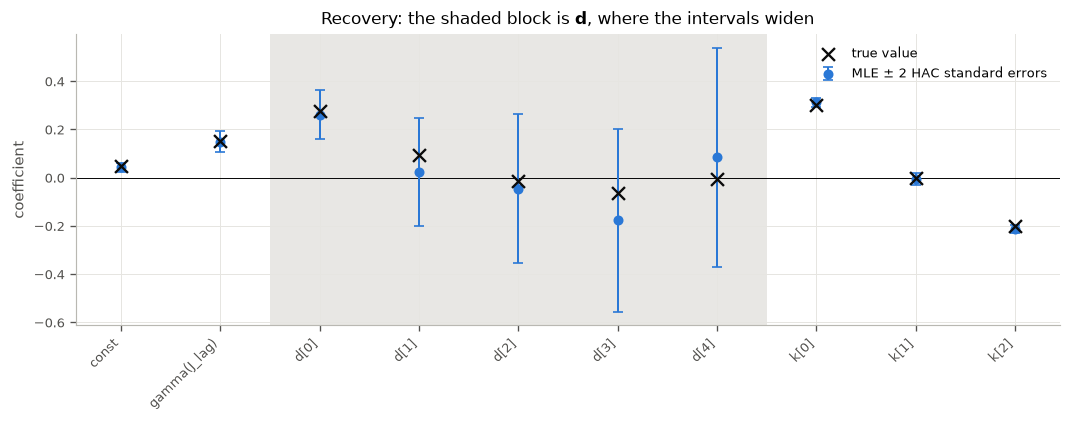

10 of 10 coefficients within 2 HAC standard errors of the truth
widths of the d-block intervals, leading to trailing: [0.1019 0.2243 0.3092 0.3797 0.4548]


In [4]:
truth = np.concatenate([[a_true, gamma_true], sim["d_true"], k_true])
pos = np.arange(fit.theta.size)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.errorbar(pos, fit.theta, yerr=2 * fit.se_hac, fmt="o", ms=5, color=MLE, capsize=3,
            lw=1.2, label=r"MLE $\pm$ 2 HAC standard errors", zorder=3)
ax.scatter(pos, truth, marker="x", s=60, color=style.INK, zorder=4, label="true value")
ax.axhline(0, color=style.INK, lw=0.6)
ax.axvspan(pos[fit.blocks["d"]][0] - 0.5, pos[fit.blocks["d"]][-1] + 0.5,
           color=style.BAND, alpha=0.6, lw=0, zorder=0)
ax.set_axisbelow(True)
ax.set_xticks(pos)
ax.set_xticklabels(fit.names, rotation=45, ha="right")
ax.set_ylabel("coefficient")
ax.set_title(r"Recovery: the shaded block is $\mathbf{d}$, where the intervals widen")
ax.legend()
plt.tight_layout()
plt.show()

inside = np.abs(fit.theta - truth) <= 2 * fit.se_hac
print(f"{inside.sum()} of {inside.size} coefficients within 2 HAC standard errors of the truth")
print(f"widths of the d-block intervals, leading to trailing: "
      f"{np.round(2 * fit.se_hac[fit.blocks['d']], 4)}")

The scalar parameters come back cleanly and the leading loading does too. What the shaded block
shows is the eigenvalue decay turning into standard errors: the intervals on $d_k$ widen by a
factor of four and a half from the first component to the fifth, because a direction carrying five per
cent of the curves' variance is a direction the data barely resolves.

## 3. Residual diagnostics

The maintained assumption is homoskedastic Gaussian $\eta_t$, and it is worth checking here
where it is true, so that the same three panels mean something when they are drawn on real
jumps and it is not. The third is the one that matters: residuals against $|J_{t-1}|$ should be
flat, and any fan shape is the volatility clustering that would motivate a conditional-variance
term the equation as written does not have.

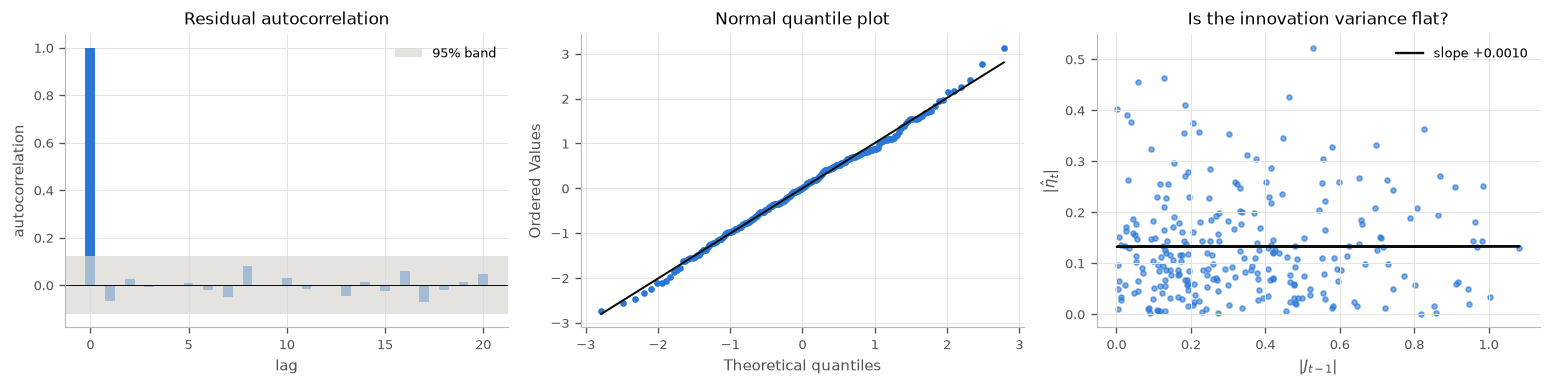

Ljung-Box on 5 lags: 1.369, p = 0.9276
Shapiro-Wilk on the residuals: p = 0.8665
slope of |residual| on |J_(t-1)|: +0.0010


In [5]:
resid = fit.resid
lagged = np.abs(sim["J"][:-1])


def acf(x, max_lag=20):
    """Sample autocorrelations of `x` to `max_lag`, lag zero first."""
    x = np.asarray(x, float) - np.mean(x)
    denom = x @ x
    return np.array([1.0] + [(x[h:] @ x[:-h]) / denom for h in range(1, max_lag + 1)])


fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
r = acf(resid)
band = 1.96 / np.sqrt(resid.size)
ax[0].bar(np.arange(r.size), r, width=0.5, color=MLE)
ax[0].axhspan(-band, band, color=style.BAND, alpha=0.7, lw=0, label="95% band")
ax[0].axhline(0, color=style.INK, lw=0.6)
ax[0].set_axisbelow(True)
ax[0].set_xlabel("lag")
ax[0].set_ylabel("autocorrelation")
ax[0].set_title("Residual autocorrelation")
ax[0].legend()

stats.probplot(resid / resid.std(), dist="norm", plot=ax[1])
ax[1].get_lines()[0].set(color=MLE, ms=3)
ax[1].get_lines()[1].set(color=style.INK, lw=1.2)
ax[1].set_title("Normal quantile plot")

ax[2].scatter(lagged, np.abs(resid), s=9, color=MLE, alpha=0.6)
slope, intercept = np.polyfit(lagged, np.abs(resid), 1)
ax[2].plot(lagged, intercept + slope * lagged, color=style.INK, lw=1.4,
           label=f"slope {slope:+.4f}")
ax[2].set_xlabel(r"$|J_{t-1}|$")
ax[2].set_ylabel(r"$|\hat\eta_t|$")
ax[2].set_title("Is the innovation variance flat?")
ax[2].legend()
plt.tight_layout()
plt.show()

lb = resid.size * (resid.size + 2) * np.sum(r[1:6] ** 2 / (resid.size - np.arange(1, 6)))
print(f"Ljung-Box on 5 lags: {lb:.3f}, p = {stats.chi2.sf(lb, 5):.4f}")
print(f"Shapiro-Wilk on the residuals: p = {stats.shapiro(resid).pvalue:.4f}")
print(f"slope of |residual| on |J_(t-1)|: {slope:+.4f}")

## 4. $\delta(u)$, and what unpenalised estimation costs

The vector $\mathbf{d}$ is an artefact of whichever basis the curves happened to produce. The
interpretable object is $\delta(u) = \sum_k d_k \hat\phi_k(u)$: *which part of yesterday's
session predicts tonight's move*. Reconstructing it is also where the MLE's lack of shrinkage
becomes visible, because a noisy loading on a high-order component is a noisy oscillation
across the whole domain.

There is a floor to how well any estimator can do here, and it belongs in the picture: the
truth $\delta$ is a function on the grid, and the estimator can only ever return something in
the span of the $M$ retained components. Projecting $\delta$ onto that span is the best
achievable reconstruction, and the gap between it and the truth is not the estimator's fault.

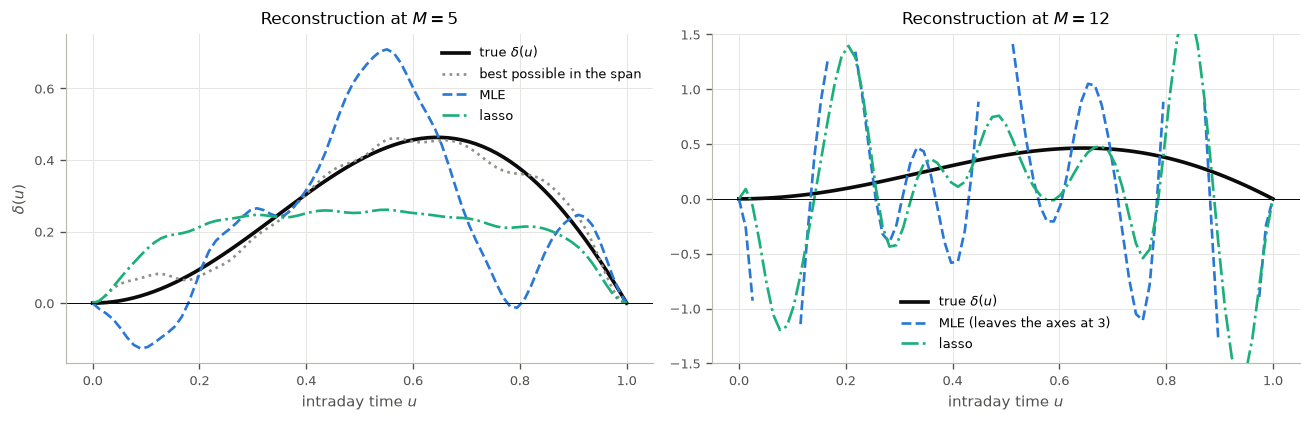

  M = 5,  MLE     L2 error in delta: 0.1673
  M = 5,  lasso   L2 error in delta: 0.1314
  M = 5,  floor   L2 error in delta: 0.0242
  M = 12, MLE     L2 error in delta: 1.2968
  M = 12, lasso   L2 error in delta: 0.7105
  M = 12, floor   L2 error in delta: 0.0065

the lasso kept 4 of 8 penalised columns at M = 5, and 7 of 15 at M = 12


In [6]:
lasso = je.fit_lasso(sim["J"], sim["psi"], sim["Z"], random_state=0)
d_mle = fit.block("d")
d_lasso = np.array([lasso["coef"][f"d[{k}]"] for k in range(M)])


def l2_error(d, basis, truth):
    """Root mean squared distance between a reconstructed delta and the true one."""
    return float(np.sqrt(np.mean((je.reconstruct_delta(d, basis) - truth) ** 2)))


fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(grid, delta_true, color=style.INK, lw=2.2, label=r"true $\delta(u)$")
ax[0].plot(grid, je.reconstruct_delta(sim["d_true"], sim["phi"]), color=style.CONTROL,
           lw=1.6, ls=":", label="best possible in the span")
ax[0].plot(grid, je.reconstruct_delta(d_mle, sim["phi"]), color=MLE, lw=1.6, ls="--",
           label="MLE")
ax[0].plot(grid, je.reconstruct_delta(d_lasso, sim["phi"]), color=LASSO, lw=1.6, ls="-.",
           label="lasso")
ax[0].axhline(0, color=style.INK, lw=0.6)
ax[0].set_xlabel("intraday time $u$")
ax[0].set_ylabel(r"$\delta(u)$")
ax[0].set_title(fr"Reconstruction at $M = {M}$")
ax[0].legend()

# The same thing with more components retained, which is the realistic case on real curves.
sim_wide = dgp.simulate_curves_and_jumps(
    n=n_sessions, a=a_true, gamma=gamma_true, delta=delta_true, snr=4.0, k=k_true,
    grid=grid, n_components=12, rng=7)
fit_wide = je.fit_mle(sim_wide["J"], sim_wide["psi"], sim_wide["Z"])
lasso_wide = je.fit_lasso(sim_wide["J"], sim_wide["psi"], sim_wide["Z"], random_state=0)
d_wide = np.array([lasso_wide["coef"][f"d[{k}]"] for k in range(12)])

shown, worst = style.clip_to(je.reconstruct_delta(fit_wide.block("d"), sim_wide["phi"]),
                             -1.5, 1.5)
ax[1].plot(grid, delta_true, color=style.INK, lw=2.2, label=r"true $\delta(u)$")
ax[1].plot(grid, shown, color=MLE, lw=1.6, ls="--",
           label=f"MLE (leaves the axes at {style.fmt(worst)})" if worst else "MLE")
ax[1].plot(grid, je.reconstruct_delta(d_wide, sim_wide["phi"]), color=LASSO, lw=1.6, ls="-.",
           label="lasso")
ax[1].axhline(0, color=style.INK, lw=0.6)
ax[1].set_ylim(-1.5, 1.5)
ax[1].set_xlabel("intraday time $u$")
ax[1].set_title(r"Reconstruction at $M = 12$")
ax[1].legend()
plt.tight_layout()
plt.show()

for label, d, s in (("M = 5,  MLE", d_mle, sim), ("M = 5,  lasso", d_lasso, sim),
                    ("M = 5,  floor", sim["d_true"], sim),
                    ("M = 12, MLE", fit_wide.block("d"), sim_wide),
                    ("M = 12, lasso", d_wide, sim_wide),
                    ("M = 12, floor", sim_wide["d_true"], sim_wide)):
    print(f"  {label:<15} L2 error in delta: {l2_error(d, s['phi'], delta_true):.4f}")
print(f"\nthe lasso kept {lasso['n_selected']} of {len(lasso['names_penalised'])} penalised "
      f"columns at M = 5, and {lasso_wide['n_selected']} of "
      f"{len(lasso_wide['names_penalised'])} at M = 12")

At five components the two estimators are close and both are some way above the floor. At twelve
they are not close at all: the MLE's reconstruction leaves the axes entirely while the best
achievable reconstruction has *improved*, because a wider span can represent $\delta$ better.
That is the whole argument for shrinkage in one number: the information available went up and
the unpenalised estimate got worse.

It is also why the lasso is here as a diagnostic rather than as the estimator. It selects its
penalty by cross-validation, which targets prediction, and an exact zero is worth more for
support recovery than for prediction; this repository measures the same split for the group
lasso in `notebooks/LocSpaFLR_f2s.ipynb`. What the penalty reliably does is order the
shrinkage, and the size of the gap it opens against the MLE is the reading to take from it.

## 5. Does serial dependence in the curves cost anything?

Real intraday curves are not independent across sessions; `notebooks/overnight_jumps.ipynb`
rejects independence for eight of nine instruments. The jump equation treats the curve as a
predetermined regressor rather than as an i.i.d. draw, so in principle it should not care. That
is a claim worth measuring rather than asserting, and `jump_dgp` will draw the curves through a
FAR(1) recursion instead, at a given Hilbert–Schmidt norm $\rho$, holding everything else fixed.

In [7]:
seeds = range(30)
sweep = {}
for rho in (0.0, 0.4, 0.7):
    errors = []
    for seed in seeds:
        one = dgp.simulate_curves_and_jumps(
            n=300, a=a_true, gamma=gamma_true, delta=delta_true, snr=4.0, grid=grid,
            n_components=4, rho=rho, rng=seed)
        errors.append(abs(je.fit_mle(one["J"], one["psi"]).theta[1] - gamma_true))
    sweep[rho] = np.array(errors)
    print(f"rho = {rho}: median |gamma_hat - gamma| = {np.median(sweep[rho]):.4f}, "
          f"mean {sweep[rho].mean():.4f}")

paired = sweep[0.7] - sweep[0.0]
t = paired.mean() / (paired.std(ddof=1) / np.sqrt(paired.size))
print(f"\npaired over {len(seeds)} seeds, rho = 0.7 against rho = 0: "
      f"mean difference {paired.mean():+.4f}, t = {t:+.3f}, "
      f"p = {2 * stats.t.sf(abs(t), paired.size - 1):.4f}")

rho = 0.0: median |gamma_hat - gamma| = 0.0185, mean 0.0200


rho = 0.4: median |gamma_hat - gamma| = 0.0260, mean 0.0239


rho = 0.7: median |gamma_hat - gamma| = 0.0231, mean 0.0238

paired over 30 seeds, rho = 0.7 against rho = 0: mean difference +0.0038, t = +1.169, p = 0.2519


Nothing that thirty paired replications can separate from zero. The median absolute error
in $\hat\gamma$ moves from 0.0185 at $\rho = 0$ to 0.0231 at $\rho = 0.7$, and paired over
the same seeds that difference is $+0.0038$ with $t = +1.17$. Thirty seeds cannot rule out
a small cost, but they rule out the kind that would matter: the estimator is indifferent
to whether the curves it conditions on are independent of each other, which is what the timing
argument predicted and what makes it usable on the real sequence.

## 6. Real sessions

Now the equation on data. Nine instruments, roughly 500 sessions each from the hourly panel: the
curve and the jump come out of one price series, `fdaSP.intraday.align_curves_to_jumps` pairs
each session's curve with the jump that follows it, and `far_est.fpca` supplies the four leading
scores. The two covariates in $\mathbf{z}$ are the session's realised volatility and its
Parkinson range, standardised, which are the two summaries `notebooks/overnight_jumps.ipynb`
found to correlate with the size of the coming jump.

The equation is fitted to two targets, because the earlier notebook found they behave
completely differently: the signed jump $J_t$, and its size $|J_t|$. Each block gets its joint
test rather than a column of $t$-statistics.

In [8]:
bars = itd.load_bars("1h")
start, end = itd.snapshot_span("1h")
rows = []
for symbol in itd.TICKERS:
    one = bars[bars["ticker"] == symbol]
    curves, grid_1h, when = itd.session_curves(one, kind="cidr")
    curves, jump, session = itd.align_curves_to_jumps(curves, when,
                                                      itd.overnight_jumps(one))
    scores = fpca(curves, grid_1h, n_components=4)["scores"]
    summary = itd.session_summary(one).loc[list(session), ["rvol", "rng"]].to_numpy()
    covariates = (summary - summary.mean(0)) / summary.std(0)
    for target, values in (("signed", 100 * jump), ("absolute", np.abs(100 * jump))):
        real = je.fit_mle(values, scores, covariates)
        rows.append({"ticker": symbol, "target": target, "n": real.nobs,
                     "gamma": real.theta[1], "p gamma": real.pvalues()[1],
                     "p delta": real.wald("d")[2], "p k": real.wald("k")[2],
                     "R2": 1 - real.sigma2 / np.var(values[1:])})

real_table = pd.DataFrame(rows).set_index(["target", "ticker"]).sort_index()
print(f"hourly panel, {start} to {end}")
print(real_table.round(4).to_string())

print()
for target in ("signed", "absolute"):
    part = real_table.loc[target]
    print(f"{target:>8}: gamma significant at 5% for {int((part['p gamma'] < 0.05).sum())} of 9,"
          f" the functional term for {int((part['p delta'] < 0.05).sum())} of 9,"
          f" the covariates for {int((part['p k'] < 0.05).sum())} of 9;"
          f" median R2 {part['R2'].median():.4f}")

hourly panel, 2024-08-29 to 2026-08-28
                   n   gamma  p gamma  p delta     p k      R2
target   ticker                                               
absolute AAPL    492  0.1737   0.0414   0.8314  0.0002  0.1093
         AMZN    492  0.1797   0.0003   0.4585  0.0020  0.0981
         MSFT    492  0.0009   0.9888   0.7317  0.0017  0.0424
         NVDA    492 -0.0299   0.5487   0.6704  0.0000  0.0759
         QQQ     492  0.0104   0.9020   0.6358  0.0000  0.1053
         SPY     492  0.0550   0.5819   0.3690  0.0000  0.1916
         TSLA    492 -0.0126   0.7884   0.2300  0.0000  0.0678
         ^FTSE   498  0.0083   0.8402   0.8022  0.0000  0.0352
         ^GSPC   492  0.0108   0.9062   0.2492  0.0000  0.1841
signed   AAPL    492  0.1002   0.2038   0.1595  0.7049  0.0252
         AMZN    492  0.1335   0.0433   0.2972  0.9592  0.0368
         MSFT    492  0.0247   0.5895   0.4415  0.0983  0.0245
         NVDA    492 -0.0127   0.8065   0.8335  0.8352  0.0054
         QQQ    

The functional term is not significant for a single instrument, on either target, while the two
scalar covariates are significant for **every** instrument on the size of the jump. That is not
a power problem: the same test on the simulated design above rejects comfortably, and the
covariate block in the very same regressions rejects at essentially any level.

An in-sample test is not the last word, so the next cell asks the same question out of sample,
on three nested models split chronologically. This is the decisive version, because adding
regressors can only raise in-sample fit and this is where a term that is not earning its place
has to pay for it.

held-out R2 on |J_t|, chronological 70/30 split:
        AR only  + covariates  + the curve
ticker                                    
AAPL    -0.0883       -0.0921      -0.1384
AMZN     0.0390        0.0416       0.0026
MSFT     0.0097        0.0452       0.0464
NVDA    -0.0121        0.0268       0.0289
TSLA     0.0172       -0.0170      -0.0260
SPY     -0.0741        0.0470      -0.0480
QQQ     -0.0377        0.0300      -0.0441
^GSPC   -0.1116        0.0173      -0.0860
^FTSE   -0.0160        0.0165      -0.0108

median: {'AR only': -0.016, '+ covariates': 0.0268, '+ the curve': -0.026}
the curve helps for 2 of 9 instruments


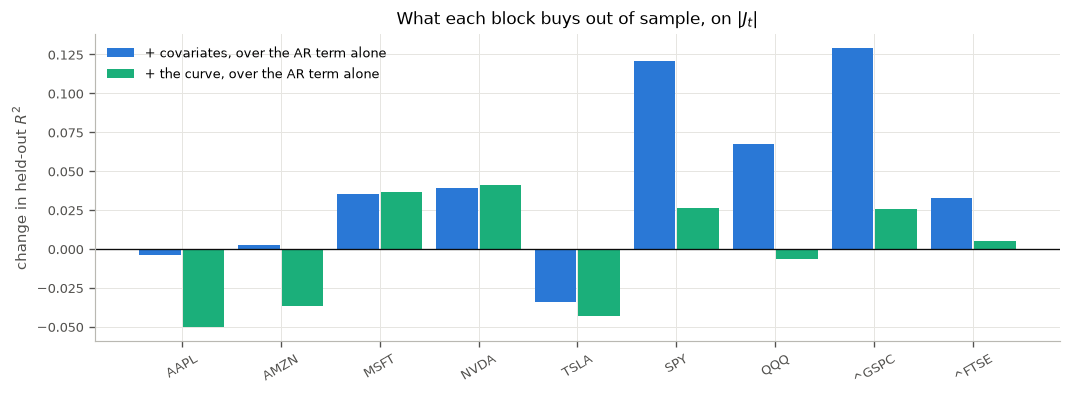

In [9]:
def nested_holdout(y, scores, covariates, frac=0.7):
    """Held-out R2 of three nested models, split chronologically at `frac` of the sample."""
    out = {}
    for label, psi, Z in (("AR only", None, None), ("+ covariates", None, covariates),
                          ("+ the curve", scores, covariates)):
        target, design, _names, _blocks = je.build_design(y, psi, Z)
        cut = int(frac * target.size)
        theta, *_ = np.linalg.lstsq(design[:cut], target[:cut], rcond=None)
        error = target[cut:] - design[cut:] @ theta
        flat = target[cut:] - target[:cut].mean()
        out[label] = 1 - float(error @ error) / float(flat @ flat)
    return out


rows = []
for symbol in itd.TICKERS:
    one = bars[bars["ticker"] == symbol]
    curves, grid_1h, when = itd.session_curves(one, kind="cidr")
    curves, jump, session = itd.align_curves_to_jumps(curves, when,
                                                      itd.overnight_jumps(one))
    scores = fpca(curves, grid_1h, n_components=4)["scores"]
    summary = itd.session_summary(one).loc[list(session), ["rvol", "rng"]].to_numpy()
    covariates = (summary - summary.mean(0)) / summary.std(0)
    rows.append({"ticker": symbol} | nested_holdout(np.abs(100 * jump), scores, covariates))

holdout = pd.DataFrame(rows).set_index("ticker")
print("held-out R2 on |J_t|, chronological 70/30 split:")
print(holdout.round(4).to_string())
print(f"\nmedian: {holdout.median().round(4).to_dict()}")
print(f"the curve helps for {int((holdout['+ the curve'] > holdout['+ covariates']).sum())} "
      f"of {len(holdout)} instruments")

fig, ax = plt.subplots(figsize=(9, 3.4))
pos = np.arange(len(holdout))
for offset, column, colour in ((-0.22, "+ covariates", MLE),
                               (0.22, "+ the curve", LASSO)):
    ax.bar(pos + offset, holdout[column] - holdout["AR only"], width=0.42, color=colour,
           label=f"{column}, over the AR term alone")
ax.axhline(0, color=style.INK, lw=0.8)
ax.set_axisbelow(True)
ax.set_xticks(pos)
ax.set_xticklabels(holdout.index, rotation=30)
ax.set_ylabel(r"change in held-out $R^2$")
ax.set_title(r"What each block buys out of sample, on $|J_t|$")
ax.legend()
plt.tight_layout()
plt.show()

## 7. What the equation says

**Maximum likelihood is feasible, closed form and well behaved.** The triangular timing lets
the jump equation be estimated on its own, and conditional MLE is least squares. Parameter
recovery is clean on simulated data, the residual diagnostics are what they should be, and
drawing the curves through a FAR(1) instead of independently costs nothing measurable. This is
the estimate to report first and to check a sampler against.

**Report Newey–West standard errors on real data.** Under the i.i.d. simulation the two sets
agree on average, their ratio over the ten
coefficients averaging 0.955. They will not agree on real jumps, whose innovation variance
persists even where the AR(1) mean is right, and the sandwich is the honest one there.

**$\delta(u)$ is the object, and it needs shrinkage.** The scalar $\mathbf{d}$ is a projection artefact. Reconstructed from the unpenalised MLE it inherits every noisy high-order loading, and the damage grows with the number of components retained. At twelve components the reconstruction leaves the axes while the best achievable one is *better* than it was at five. More information, worse estimate. That is the case for a shrinkage prior on the $\mathbf{d}$ block stated as a measurement rather than as a preference.

**On real sessions the functional term is empty and the covariate term is not.** Across nine
instruments and both targets, the joint test that $\delta \equiv 0$ rejects for none, while the
test that $\mathbf{k} = \mathbf{0}$ rejects for all nine on $|J_t|$. Out of sample the ordering
is the same: adding the two scalar summaries lifts the median held-out $R^2$ from below zero to
above it, and adding the curve on top of them puts it back below.

That is the finding `notebooks/overnight_jumps.ipynb` reaches by a different route, arriving
here as a parameter restriction. A bounded $\delta$ integrated against $X$ cannot evaluate $X$
at a point, so when a curve's informative summary is one of its values (its endpoint, or a
functional of the session's magnitude rather than its shape) the functional slot cannot express
it and the unpenalised block simply adds variance. The equation's $\mathbf{z}_t^\top \mathbf{k}$
term, usually treated as somewhere to park nuisance covariates, is where the signal in this
problem actually lives.

The open item is the one the standard errors above do not address. The scores are generated
regressors, and both `se_ols` and `se_hac` condition on the decomposition, so the reported
uncertainty in $\mathbf{d}$ is too small by an amount neither of them measures. Bootstrapping
over the FPCA step is the next thing to build; it does not change the conclusions here, since
those rest on failures to reject that a wider interval could only reinforce.